Task 01: Implement the task performed in the lab manual mentioned in the lab number 6 but the data should be of your own choice and not the one mentioned in the lab manual.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "wine-clustering.csv"

df = pd.read_csv(dataset_path)
df .head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [47]:
Numerical_features = ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline']

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


In [48]:
df = df.astype({'Alcohol': 'int', 'Malic_Acid': 'int', 'Ash': 'int', 'Ash_Alcanity': 'int', 'Magnesium': 'int', 'Total_Phenols': 'int', 'Flavanoids': 'int', 'Nonflavanoid_Phenols': 'int', 'Proanthocyanins': 'int', 'Color_Intensity': 'int', 'Hue': 'int', 'OD280': 'int', 'Proline': 'int'})

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Alcohol               178 non-null    int64
 1   Malic_Acid            178 non-null    int64
 2   Ash                   178 non-null    int64
 3   Ash_Alcanity          178 non-null    int64
 4   Magnesium             178 non-null    int64
 5   Total_Phenols         178 non-null    int64
 6   Flavanoids            178 non-null    int64
 7   Nonflavanoid_Phenols  178 non-null    int64
 8   Proanthocyanins       178 non-null    int64
 9   Color_Intensity       178 non-null    int64
 10  Hue                   178 non-null    int64
 11  OD280                 178 non-null    int64
 12  Proline               178 non-null    int64
dtypes: int64(13)
memory usage: 18.2 KB


In [49]:
df.isnull().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

In [50]:
print(df[Numerical_features].agg(['min', 'max']))

     Alcohol  Malic_Acid  Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
min       11           0    1            10         70              0   
max       14           5    3            30        162              3   

     Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity  Hue  \
min           0                     0                0                1    0   
max           5                     0                3               13    1   

     OD280  Proline  
min      1      278  
max      4     1680  


In [51]:
# Apply Min-Max scaling without changing the original dataset
df_MinMax = (
    df[Numerical_features] - df[Numerical_features].min()
) / (
    df[Numerical_features].max() - df[Numerical_features].min()
)

df_MinMax.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1.000000,0.2,0.5,0.25,0.619565,0.666667,0.6,NaN,0.666667,0.333333,1.0,0.666667,0.561341
1,0.666667,0.2,0.5,0.05,0.326087,0.666667,0.4,NaN,0.333333,0.250000,1.0,0.666667,0.550642
2,0.666667,0.4,0.5,0.40,0.336957,0.666667,0.6,NaN,0.666667,0.333333,1.0,0.666667,0.646933
3,1.000000,0.2,0.5,0.30,0.467391,1.000000,0.6,NaN,0.666667,0.500000,0.0,0.666667,0.857347
4,0.666667,0.4,0.5,0.55,0.521739,0.666667,0.4,NaN,0.333333,0.250000,1.0,0.333333,0.325963


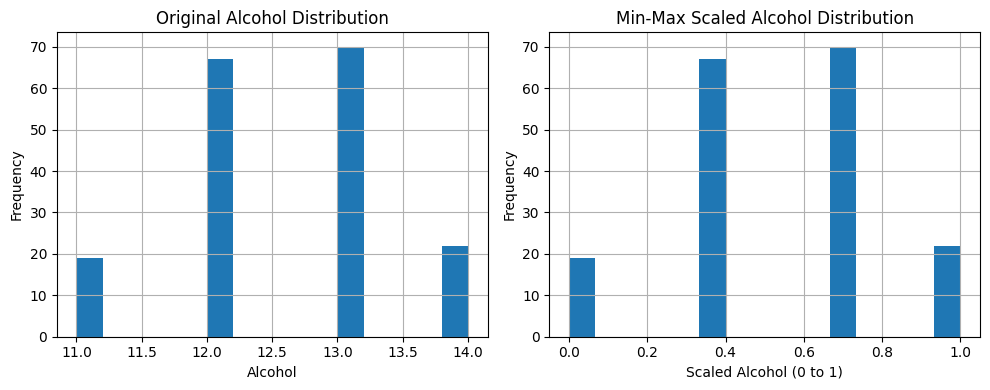

In [56]:
# Single plot for both original and scaled data
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
df['Alcohol'].hist(bins=15)
plt.title("Original Alcohol Distribution")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
df_MinMax['Alcohol'].hist(bins=15)
plt.title("Min-Max Scaled Alcohol Distribution")
plt.xlabel("Scaled Alcohol (0 to 1)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()